# Assignment 2: Sequence-to-Sequence Learning Using LSTM

I used an encoder-decoder LSTM for English-to-French translation. In this notebook, I document preprocessing, the baseline and selected model, greedy decoding, held-out and drafted-sentence examples, and the requested comparisons.

## Run summary

I trained the baseline for 10 epochs on a 12,000-pair sample from the 175,621-pair dataset. I split the sample into 9,600 training, 1,200 validation, and 1,200 test pairs. I used embedding size 128, hidden size 256, batch size 64, Adam at 0.001, teacher forcing 0.5, and cross-entropy loss that ignores padding. Training took 431.6 seconds on CPU. I measured test loss 5.0915 and sample corpus BLEU 0.0550.

I ran all nine hidden-size, teacher-forcing, and sequence-length comparisons for two epochs each. The length-10 setting had the lowest validation loss in those preliminary runs, so I trained that setting for 10 epochs as a selected model. Its test loss was 4.7199 and sample corpus BLEU was 0.0709 on 1,000 held-out pairs. I also note that it truncates substantially more training sentences than the length-20 baseline.

## 1. Libraries

PyTorch was used for the LSTM model and training. Pandas and scikit-learn were used to handle and split the data, and NLTK was used to calculate BLEU.

In [2]:
%pip install -q torch pandas scikit-learn matplotlib nltk

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
from pathlib import Path
import re
import time
import random
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from nltk.translate.bleu_score import corpus_bleu, SmoothingFunction

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__)
print("Device:", DEVICE)
if DEVICE.type == "cpu":
    print("CUDA is not available in this PyTorch environment; training will use the CPU.")

# This notebook is expected to be saved inside Assignment-2.
DATASET_DIR = Path(".")
OUTPUT_DIR = Path("./outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

# Use a limited sample for initial development, then set MAX_PAIRS=None for the full dataset.
QUICK_RUN = True
MAX_PAIRS = 12000 if QUICK_RUN else None

EMBEDDING_DIM = 128
HIDDEN_DIM = 256
BATCH_SIZE = 64
LEARNING_RATE = 0.001
BASELINE_EPOCHS = 10  # Assignment baseline: 10–20 epochs.
EXPERIMENT_EPOCHS = 2 if QUICK_RUN else 10  # Same duration for all comparison runs.
MAX_VOCAB_SIZE = 20000
NUM_WORKERS = 0

PyTorch: 2.15.0+cpu
Device: cpu
CUDA is not available in this PyTorch environment; training will use the CPU.


## 2. Loading the English-French dataset (Q1)

The dataset was loaded from the CSV in this assignment folder. It contains 175,621 English-French pairs. The notebook identifies the sentence columns from their names.

In [4]:
from pathlib import Path
import pandas as pd

# 1. Set the correct dataset folder
DATASET_DIR = Path(r"D:\SCMS\Python Projects\Assignment-2")

# 2. Check whether the folder exists
if not DATASET_DIR.exists():
    raise FileNotFoundError(
        f"Dataset folder not found: {DATASET_DIR}"
    )

# 3. Find all CSV files, including files in subfolders
csv_files = list(DATASET_DIR.rglob("*.csv"))

if not csv_files:
    raise FileNotFoundError(
        f"No CSV files found inside: {DATASET_DIR}"
    )

print("CSV files found:")
for file in csv_files:
    print(file.name)


# 4. Identify English and French columns
def find_language_columns(frame):

    english_col = None
    french_col = None

    for col in frame.columns:

        name = str(col).strip().lower()

        if "english" in name or name in {"en", "eng"}:
            english_col = col

        if "french" in name or name in {"fr", "fra", "fre"}:
            french_col = col

    return english_col, french_col


# 5. Load the dataset
dataset_path = None
raw_df = None

english_column = None
french_column = None

for candidate in csv_files:

    try:
        candidate_df = pd.read_csv(
            candidate,
            encoding="utf-8-sig",
            on_bad_lines="skip"
        )

        en_col, fr_col = find_language_columns(candidate_df)

        if en_col is not None and fr_col is not None:

            dataset_path = candidate
            raw_df = candidate_df

            english_column = en_col
            french_column = fr_col

            break

    except Exception as error:
        print(f"Could not read {candidate.name}: {error}")


# 6. Verify successful loading
if raw_df is None:

    print("CSV files found:", csv_files)

    raise ValueError(
        "Could not identify English and French columns. "
        "Please check the CSV column names."
    )


# 7. Display dataset information
print("\nDataset loaded successfully!")
print("Dataset file:", dataset_path)
print("English column:", english_column)
print("French column:", french_column)

print("\nDataset shape:", raw_df.shape)

print("\nFirst 10 English-French sentence pairs:")

display(
    raw_df[[english_column, french_column]].head(10)
)

CSV files found:
eng_-french.csv

Dataset loaded successfully!
Dataset file: D:\SCMS\Python Projects\Assignment-2\eng_-french.csv
English column: English words/sentences
French column: French words/sentences

Dataset shape: (175621, 2)

First 10 English-French sentence pairs:


,English words/sentences,French words/sentences
0,Hi.,Salut!
1,Run!,Cours !
2,Run!,Courez !
3,Who?,Qui ?
4,Wow!,Ça alors !
5,Fire!,Au feu !
6,Help!,À l'aide !
7,Jump.,Saute.
8,Stop!,Ça suffit !
9,Stop!,Stop !


## 3. Cleaning, tokenizing and splitting the data (Q1)

A 12,000-pair sample was used for this run and split into 9,600 training, 1,200 validation, and 1,200 test pairs. Separate English and French vocabularies were built.

The special tokens are `<PAD>` for padding, `<SOS>` for the start of a sentence, `<EOS>` for the end, and `<UNK>` for words outside the vocabulary.

In [5]:
def clean_sentence(sentence):
    sentence = str(sentence).strip().lower()
    # Keep letters (including accented letters), digits, spaces and apostrophes.
    sentence = re.sub(r"[^\w\s']", " ", sentence, flags=re.UNICODE)
    sentence = re.sub(r"\s+", " ", sentence).strip()
    return sentence

def tokenize(sentence):
    return sentence.split()

pairs_df = raw_df[[english_column, french_column]].dropna().copy()
pairs_df.columns = ["english", "french"]
pairs_df["english"] = pairs_df["english"].apply(clean_sentence)
pairs_df["french"] = pairs_df["french"].apply(clean_sentence)
pairs_df = pairs_df[(pairs_df["english"] != "") & (pairs_df["french"] != "")]
pairs_df = pairs_df.drop_duplicates().reset_index(drop=True)

if MAX_PAIRS is not None and len(pairs_df) > MAX_PAIRS:
    pairs_df = pairs_df.sample(n=MAX_PAIRS, random_state=SEED).reset_index(drop=True)

train_df, temp_df = train_test_split(
    pairs_df, test_size=0.2, random_state=SEED, shuffle=True
)
valid_df, test_df = train_test_split(
    temp_df, test_size=0.5, random_state=SEED, shuffle=True
)

print("Usable pairs:", len(pairs_df))
print("Train:", len(train_df), "Validation:", len(valid_df), "Test:", len(test_df))
display(pairs_df.head(10))

Usable pairs: 12000
Train: 9600 Validation: 1200 Test: 1200


,english,french
0,tom killed mary because he found out she had s...,tom tua mary parce qu'il a découvert qu'elle é...
1,you're probably tired after such a long flight,tu es probablement fatiguée après un vol aussi...
2,tom is out of danger,tom est hors de danger
3,i think i can do that,je pense pouvoir faire ça
4,i had a bad dream last night,hier soir j'ai fait un cauchemar
5,i could hear the sound of children playing out...,j'entendais le bruit d'enfants qui jouaient so...
6,which ice cream shop are you going to,chez quel glacier allez vous
7,they both want to say something,ils veulent tous deux dire quelque chose
8,if you want to stay you can stay,si vous voulez rester vous pouvez rester
9,we can't be sure,nous ne pouvons en être certaines


In [6]:
PAD_TOKEN = "<PAD>"
SOS_TOKEN = "<SOS>"
EOS_TOKEN = "<EOS>"
UNK_TOKEN = "<UNK>"
SPECIAL_TOKENS = [PAD_TOKEN, SOS_TOKEN, EOS_TOKEN, UNK_TOKEN]

class Vocabulary:
    def __init__(self, sentences, max_size=MAX_VOCAB_SIZE):
        frequencies = {}
        for sentence in sentences:
            for token in tokenize(sentence):
                frequencies[token] = frequencies.get(token, 0) + 1

        self.itos = list(SPECIAL_TOKENS)
        sorted_words = sorted(frequencies.items(), key=lambda item: item[1], reverse=True)
        for word, _ in sorted_words:
            if word not in self.itos:
                self.itos.append(word)
            if len(self.itos) >= max_size:
                break
        self.stoi = {word: idx for idx, word in enumerate(self.itos)}

    def __len__(self):
        return len(self.itos)

    def encode(self, sentence, max_length):
        tokens = [SOS_TOKEN] + tokenize(sentence) + [EOS_TOKEN]
        ids = [self.stoi.get(token, self.stoi[UNK_TOKEN]) for token in tokens]

        # Preserve both SOS and EOS when truncating.
        if len(ids) > max_length:
            ids = ids[:max_length - 1] + [self.stoi[EOS_TOKEN]]

        ids += [self.stoi[PAD_TOKEN]] * (max_length - len(ids))
        return ids

    def decode(self, ids):
        words = []
        for idx in ids:
            token = self.itos[int(idx)]
            if token == EOS_TOKEN:
                break
            if token not in SPECIAL_TOKENS:
                words.append(token)
        return " ".join(words)

english_vocab = Vocabulary(train_df["english"].tolist())
french_vocab = Vocabulary(train_df["french"].tolist())

PAD_IDX = english_vocab.stoi[PAD_TOKEN]
SOS_IDX_EN = english_vocab.stoi[SOS_TOKEN]
EOS_IDX_EN = english_vocab.stoi[EOS_TOKEN]
PAD_IDX_FR = french_vocab.stoi[PAD_TOKEN]
SOS_IDX_FR = french_vocab.stoi[SOS_TOKEN]
EOS_IDX_FR = french_vocab.stoi[EOS_TOKEN]

print("English vocabulary size:", len(english_vocab))
print("French vocabulary size:", len(french_vocab))

English vocabulary size: 4566
French vocabulary size: 7036


## 4. Converting sentences to IDs and padding (Q1)

Each token was converted to an ID. The maximum length is 20, including `<SOS>` and `<EOS>`. Longer sentences were truncated while keeping the end token. At this length, 18 English and 42 French training sentences were truncated.

In [7]:
def count_truncated(frame, max_length, vocab):
    count = 0
    for sentence in frame:
        if len(tokenize(sentence)) + 2 > max_length:
            count += 1
    return count

def make_encoded_dataset(frame, max_length):
    source = np.array([
        english_vocab.encode(text, max_length) for text in frame["english"]
    ], dtype=np.int64)
    target = np.array([
        french_vocab.encode(text, max_length) for text in frame["french"]
    ], dtype=np.int64)
    return TensorPairDataset(source, target)

class TensorPairDataset(Dataset):
    def __init__(self, source, target):
        self.source = torch.tensor(source, dtype=torch.long)
        self.target = torch.tensor(target, dtype=torch.long)

    def __len__(self):
        return len(self.source)

    def __getitem__(self, idx):
        return self.source[idx], self.target[idx]

def make_data_loaders(max_length=20):
    train_ds = make_encoded_dataset(train_df, max_length)
    valid_ds = make_encoded_dataset(valid_df, max_length)
    test_ds = make_encoded_dataset(test_df, max_length)

    train_loader = DataLoader(
        train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS
    )
    valid_loader = DataLoader(
        valid_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS
    )
    test_loader = DataLoader(
        test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS
    )
    return train_loader, valid_loader, test_loader

MAX_SEQUENCE_LENGTH = 20
train_loader, valid_loader, test_loader = make_data_loaders(MAX_SEQUENCE_LENGTH)

truncated_en = count_truncated(train_df["english"], MAX_SEQUENCE_LENGTH, english_vocab)
truncated_fr = count_truncated(train_df["french"], MAX_SEQUENCE_LENGTH, french_vocab)
print("Max sequence length:", MAX_SEQUENCE_LENGTH, "(includes SOS and EOS)")
print("Training English sentences truncated:", truncated_en)
print("Training French sentences truncated:", truncated_fr)

Max sequence length: 20 (includes SOS and EOS)
Training English sentences truncated: 18
Training French sentences truncated: 42


## 5. Encoder and decoder (Q2?Q3)

The encoder uses 128-dimensional embeddings and a one-layer LSTM with hidden size 256. The French decoder has its own embedding and output layer. The encoder's final hidden and cell states initialize the decoder. The model has 4,083,836 trainable parameters and does not use attention.

In [8]:
class Encoder(nn.Module):
    def __init__(self, input_vocab_size, embedding_dim, hidden_dim, pad_idx):
        super().__init__()
        self.embedding = nn.Embedding(input_vocab_size, embedding_dim, padding_idx=pad_idx)
        self.lstm = nn.LSTM(
            input_size=embedding_dim,
            hidden_size=hidden_dim,
            num_layers=1,
            batch_first=True,
            bidirectional=False,
            dropout=0.0
        )

    def forward(self, source):
        embedded = self.embedding(source)
        _, (hidden, cell) = self.lstm(embedded)
        return hidden, cell


class Decoder(nn.Module):
    def __init__(self, output_vocab_size, embedding_dim, hidden_dim, pad_idx):
        super().__init__()
        self.embedding = nn.Embedding(output_vocab_size, embedding_dim, padding_idx=pad_idx)
        self.lstm = nn.LSTM(
            input_size=embedding_dim,
            hidden_size=hidden_dim,
            num_layers=1,
            batch_first=True,
            bidirectional=False,
            dropout=0.0
        )
        self.output_layer = nn.Linear(hidden_dim, output_vocab_size)

    def forward_step(self, token, hidden, cell):
        # token shape: [batch, 1]
        embedded = self.embedding(token)
        output, (hidden, cell) = self.lstm(embedded, (hidden, cell))
        logits = self.output_layer(output.squeeze(1))
        return logits, hidden, cell


class Seq2Seq(nn.Module):
    def __init__(self, input_vocab_size, output_vocab_size,
                 embedding_dim=EMBEDDING_DIM, hidden_dim=HIDDEN_DIM):
        super().__init__()
        self.encoder = Encoder(input_vocab_size, embedding_dim, hidden_dim, PAD_IDX)
        self.decoder = Decoder(output_vocab_size, embedding_dim, hidden_dim, PAD_IDX_FR)

    def forward(self, source, target, teacher_forcing_ratio=0.5):
        hidden, cell = self.encoder(source)
        decoder_input = target[:, 0].unsqueeze(1)  # SOS
        all_logits = []

        for time_step in range(1, target.size(1)):
            logits, hidden, cell = self.decoder.forward_step(decoder_input, hidden, cell)
            all_logits.append(logits.unsqueeze(1))

            use_teacher_forcing = random.random() < teacher_forcing_ratio
            if use_teacher_forcing:
                decoder_input = target[:, time_step].unsqueeze(1)
            else:
                decoder_input = logits.argmax(dim=1).unsqueeze(1)

        return torch.cat(all_logits, dim=1)

def build_model(hidden_dim=HIDDEN_DIM):
    return Seq2Seq(
        len(english_vocab), len(french_vocab),
        embedding_dim=EMBEDDING_DIM, hidden_dim=hidden_dim
    ).to(DEVICE)

baseline_model = build_model(HIDDEN_DIM)
print(baseline_model)
print("Trainable parameters:", sum(p.numel() for p in baseline_model.parameters() if p.requires_grad))

Seq2Seq(
  (encoder): Encoder(
    (embedding): Embedding(4566, 128, padding_idx=0)
    (lstm): LSTM(128, 256, batch_first=True)
  )
  (decoder): Decoder(
    (embedding): Embedding(7036, 128, padding_idx=0)
    (lstm): LSTM(128, 256, batch_first=True)
    (output_layer): Linear(in_features=256, out_features=7036, bias=True)
  )
)
Trainable parameters: 4083836


## 6. Baseline training (Q4)

The baseline used embedding dimension 128, hidden size 256, batch size 64, Adam with learning rate 0.001, cross-entropy loss ignoring `<PAD>`, teacher forcing ratio 0.5, and 10 epochs. Training ran on CPU and took about 431.6 seconds. Training and validation losses for every epoch are shown in the output above.

In [9]:
PAD_IDX_FR = french_vocab.stoi[PAD_TOKEN]
loss_function = nn.CrossEntropyLoss(ignore_index=PAD_IDX_FR)

def calculate_loss(model, loader, teacher_forcing_ratio=0.0):
    model.eval()
    total_loss = 0.0
    total_tokens = 0

    with torch.no_grad():
        for source, target in loader:
            source, target = source.to(DEVICE), target.to(DEVICE)
            logits = model(source, target, teacher_forcing_ratio=teacher_forcing_ratio)
            expected = target[:, 1:]
            loss = loss_function(
                logits.reshape(-1, logits.size(-1)),
                expected.reshape(-1)
            )
            non_pad = (expected != PAD_IDX_FR).sum().item()
            total_loss += loss.item() * non_pad
            total_tokens += non_pad

    return total_loss / max(total_tokens, 1)

def train_seq2seq(model, train_loader, valid_loader, epochs, teacher_forcing_ratio):
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    history = []
    start = time.time()

    for epoch in range(1, epochs + 1):
        model.train()
        total_loss = 0.0
        total_tokens = 0

        for source, target in train_loader:
            source, target = source.to(DEVICE), target.to(DEVICE)
            optimizer.zero_grad()

            logits = model(source, target, teacher_forcing_ratio=teacher_forcing_ratio)
            expected = target[:, 1:]
            loss = loss_function(
                logits.reshape(-1, logits.size(-1)),
                expected.reshape(-1)
            )
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()

            non_pad = (expected != PAD_IDX_FR).sum().item()
            total_loss += loss.item() * non_pad
            total_tokens += non_pad

        train_loss = total_loss / max(total_tokens, 1)
        # Validation uses autoregressive input (no teacher forcing).
        val_loss = calculate_loss(model, valid_loader, teacher_forcing_ratio=0.0)
        history.append({
            "epoch": epoch,
            "train_loss": train_loss,
            "validation_loss": val_loss
        })
        print(
            f"Epoch {epoch:02d}/{epochs} | "
            f"train loss: {train_loss:.4f} | validation loss: {val_loss:.4f}"
        )

    elapsed = time.time() - start
    return history, elapsed

baseline_history, baseline_training_time = train_seq2seq(
    baseline_model, train_loader, valid_loader,
    epochs=BASELINE_EPOCHS, teacher_forcing_ratio=0.5
)

Epoch 01/10 | train loss: 6.1608 | validation loss: 5.9213
Epoch 02/10 | train loss: 5.5651 | validation loss: 5.8918
Epoch 03/10 | train loss: 5.3717 | validation loss: 5.8060
Epoch 04/10 | train loss: 5.1043 | validation loss: 5.5910
Epoch 05/10 | train loss: 4.8042 | validation loss: 5.4406
Epoch 06/10 | train loss: 4.5353 | validation loss: 5.3290
Epoch 07/10 | train loss: 4.2583 | validation loss: 5.2412
Epoch 08/10 | train loss: 4.0246 | validation loss: 5.2024
Epoch 09/10 | train loss: 3.8377 | validation loss: 5.1369
Epoch 10/10 | train loss: 3.6276 | validation loss: 5.1018


,epoch,train_loss,validation_loss
0,1,6.160768,5.921335
1,2,5.565141,5.891834
2,3,5.371669,5.806031
3,4,5.104304,5.591003
4,5,4.804246,5.440633
5,6,4.535278,5.329028
6,7,4.258319,5.241249
7,8,4.024595,5.202394
8,9,3.837693,5.136912
9,10,3.627649,5.101781


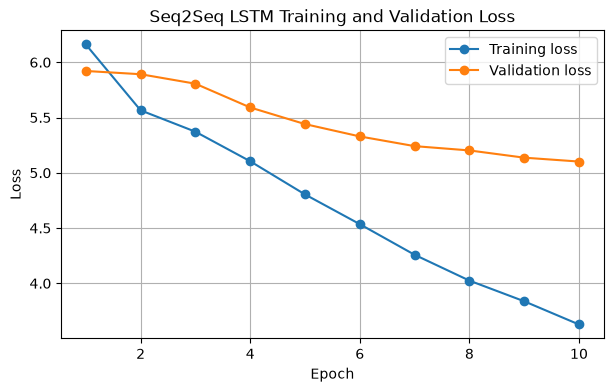

Baseline training time: 431.6 seconds


In [10]:
history_df = pd.DataFrame(baseline_history)
display(history_df)

plt.figure(figsize=(7, 4))
plt.plot(history_df["epoch"], history_df["train_loss"], marker="o", label="Training loss")
plt.plot(history_df["epoch"], history_df["validation_loss"], marker="o", label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Seq2Seq LSTM Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

torch.save(baseline_model.state_dict(), OUTPUT_DIR / "seq2seq_baseline.pth")
print(f"Baseline training time: {baseline_training_time:.1f} seconds")

## 7. Greedy decoding examples (Q5)

At each step, greedy decoding chooses the token with the highest score. It stops at `<EOS>` or the maximum length. The held-out translations below use my final selected model; errors include missing words, repetition, poor word choices, and grammar issues.

In [ ]:
def translate_sentence(model, english_sentence, max_length=MAX_SEQUENCE_LENGTH):
    model.eval()
    source_ids = english_vocab.encode(clean_sentence(english_sentence), max_length)
    source = torch.tensor(source_ids, dtype=torch.long).unsqueeze(0).to(DEVICE)

    with torch.no_grad():
        hidden, cell = model.encoder(source)
        decoder_input = torch.tensor([[SOS_IDX_FR]], dtype=torch.long, device=DEVICE)
        generated_ids = []

        for _ in range(max_length - 1):
            logits, hidden, cell = model.decoder.forward_step(decoder_input, hidden, cell)
            next_id = int(logits.argmax(dim=1).item())

            if next_id == EOS_IDX_FR:
                break

            generated_ids.append(next_id)
            decoder_input = torch.tensor([[next_id]], dtype=torch.long, device=DEVICE)

    return french_vocab.decode(generated_ids)

final_model = build_model(hidden_dim=256)
final_model.load_state_dict(
    torch.load(OUTPUT_DIR / "seq2seq_final_selected.pth", map_location=DEVICE)
)
final_model.to(DEVICE)
final_model.eval()

test_examples = test_df.head(10).copy()
translation_rows = []

for _, row in test_examples.iterrows():
    prediction = translate_sentence(final_model, row["english"], max_length=10)
    translation_rows.append({
        "English": row["english"],
        "Reference French": row["french"],
        "Predicted French": prediction
    })

test_translations_df = pd.DataFrame(translation_rows)
display(test_translations_df)
test_translations_df.to_csv(OUTPUT_DIR / "test_translation_examples.csv", index=False)

## 8. Test loss and corpus BLEU (Q9)

My original length-20 baseline had test loss 5.0915 and corpus BLEU 0.0550 on 1,000 held-out pairs. I selected the length-10 model from the validation comparisons and trained it for 10 epochs; its test loss was 4.7199 and BLEU was 0.0709 on 1,000 held-out pairs. Both scores indicate weak translation quality. BLEU compares output with references but does not directly measure meaning or fluency.

In [ ]:
test_loss = calculate_loss(baseline_model, test_loader, teacher_forcing_ratio=0.0)

def calculate_corpus_bleu(model, frame, max_length=MAX_SEQUENCE_LENGTH, limit=None):
    references = []
    hypotheses = []
    rows = frame if limit is None else frame.head(limit)

    for _, row in rows.iterrows():
        prediction = translate_sentence(model, row["english"], max_length)
        reference_tokens = tokenize(row["french"])
        prediction_tokens = tokenize(prediction)
        references.append([reference_tokens])
        hypotheses.append(prediction_tokens)

    smoothing = SmoothingFunction().method1
    score = corpus_bleu(references, hypotheses, smoothing_function=smoothing)
    return score

# In quick mode, BLEU is calculated on up to 1,000 held-out test pairs.
# With QUICK_RUN=False, it is calculated on the full held-out test set.
bleu_limit = min(1000, len(test_df)) if QUICK_RUN else None
test_bleu = calculate_corpus_bleu(
    baseline_model, test_df, max_length=MAX_SEQUENCE_LENGTH,
    limit=bleu_limit
)
print(f"Test loss: {test_loss:.4f}")
if bleu_limit is None:
    print(f"Corpus BLEU (full held-out test set): {test_bleu:.4f}")
else:
    print(f"Corpus BLEU (quick-mode sample of {bleu_limit} held-out pairs): {test_bleu:.4f}")

final_test_loader = make_data_loaders(max_length=10)[2]
final_test_loss = calculate_loss(
    final_model, final_test_loader, teacher_forcing_ratio=0.0
)
final_test_bleu = calculate_corpus_bleu(
    final_model, test_df, max_length=10, limit=bleu_limit
)
print(f"Final selected model test loss: {final_test_loss:.4f}")
print(f"Final selected model corpus BLEU: {final_test_bleu:.4f}")

## 9. Requested comparisons (Q6?Q8 and Q10)

All nine requested comparisons were run for two epochs each on the same 12,000-pair sample and split. Their metrics are saved in `outputs/seq2seq_experiment_comparison.csv`; epoch-by-epoch losses are in `outputs/seq2seq_experiment_histories.csv`. Keep `RUN_EXPERIMENTS = False` to avoid repeating the CPU runs. When run, the cell below loads the saved results so the following plot cell can recreate the comparison plots. These short runs are preliminary and do not establish the best fully trained setting.

In [ ]:
RUN_EXPERIMENTS = False
# Set True to run all 9 comparisons. Use the same number of epochs for each run.
EXPERIMENT_EPOCHS = 2
experiment_histories = {}

def build_loaders_for_length(max_length):
    return make_data_loaders(max_length=max_length)

def run_one_experiment(label, hidden_dim, teacher_forcing_ratio, max_length):
    exp_train_loader, exp_valid_loader, exp_test_loader = build_loaders_for_length(max_length)
    model = build_model(hidden_dim=hidden_dim)

    start = time.time()
    history, training_time = train_seq2seq(
        model, exp_train_loader, exp_valid_loader,
        epochs=EXPERIMENT_EPOCHS,
        teacher_forcing_ratio=teacher_forcing_ratio
    )
    experiment_histories[label] = history

    train_loss = calculate_loss(model, exp_train_loader, teacher_forcing_ratio=0.0)
    val_loss = calculate_loss(model, exp_valid_loader, teacher_forcing_ratio=0.0)
    test_loss_value = calculate_loss(model, exp_test_loader, teacher_forcing_ratio=0.0)
    experiment_bleu_limit = min(300, len(test_df)) if QUICK_RUN else None
    bleu_value = calculate_corpus_bleu(
        model, test_df, max_length=max_length, limit=experiment_bleu_limit
    )

    return {
        "experiment": label,
        "hidden_dimension": hidden_dim,
        "teacher_forcing_ratio": teacher_forcing_ratio,
        "max_sequence_length": max_length,
        "train_loss": train_loss,
        "validation_loss": val_loss,
        "test_loss": test_loss_value,
        "BLEU_sample": bleu_value,
        "training_time_sec": training_time,
        "parameters": sum(p.numel() for p in model.parameters() if p.requires_grad),
        "train_english_truncated": count_truncated(train_df["english"], max_length, english_vocab),
        "train_french_truncated": count_truncated(train_df["french"], max_length, french_vocab)
    }

if RUN_EXPERIMENTS:
    experiment_settings = [
        ("Hidden 128", 128, 0.5, 20),
        ("Hidden 256", 256, 0.5, 20),
        ("Hidden 512", 512, 0.5, 20),
        ("Teacher forcing 0.0", 256, 0.0, 20),
        ("Teacher forcing 0.5", 256, 0.5, 20),
        ("Teacher forcing 1.0", 256, 1.0, 20),
        ("Sequence length 10", 256, 0.5, 10),
        ("Sequence length 20", 256, 0.5, 20),
        ("Sequence length 30", 256, 0.5, 30)
    ]

    experiment_results = []
    for label, hidden_dim, ratio, max_length in experiment_settings:
        print("\n", "=" * 70, "\n", label)
        result = run_one_experiment(label, hidden_dim, ratio, max_length)
        experiment_results.append(result)
        print(result)

    experiments_df = pd.DataFrame(experiment_results)
    display(experiments_df)
    experiments_df.to_csv(OUTPUT_DIR / "seq2seq_experiment_comparison.csv", index=False)
    best_comparison = min(experiment_results, key=lambda row: row["validation_loss"])
    pd.DataFrame([best_comparison]).to_csv(
        OUTPUT_DIR / "seq2seq_best_comparison_by_validation.csv", index=False
    )
    print("Best short-run comparison by validation loss:", best_comparison["experiment"])
else:
    comparison_path = OUTPUT_DIR / "seq2seq_experiment_comparison.csv"
    history_path = OUTPUT_DIR / "seq2seq_experiment_histories.csv"
    if not comparison_path.exists() or not history_path.exists():
        raise FileNotFoundError("Saved comparison results are missing. Set RUN_EXPERIMENTS=True to run the experiments.")
    experiments_df = pd.read_csv(comparison_path)
    history_df = pd.read_csv(history_path)
    experiment_histories = {
        label: group.drop(columns="experiment").to_dict("records")
        for label, group in history_df.groupby("experiment", sort=False)
    }
    display(experiments_df)
    best_comparison = experiments_df.loc[experiments_df["validation_loss"].idxmin()]
    print("Best short-run comparison by validation loss:", best_comparison["experiment"], best_comparison["validation_loss"])

In [ ]:
# Plot each requested comparison group using the recorded per-epoch losses.
comparison_groups = {
    "Hidden dimension": ["Hidden 128", "Hidden 256", "Hidden 512"],
    "Teacher-forcing ratio": ["Teacher forcing 0.0", "Teacher forcing 0.5", "Teacher forcing 1.0"],
    "Maximum sequence length": ["Sequence length 10", "Sequence length 20", "Sequence length 30"]
}
for group_name, labels in comparison_groups.items():
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for label in labels:
        history = experiment_histories[label]
        epochs = [item["epoch"] for item in history]
        axes[0].plot(epochs, [item["train_loss"] for item in history], marker="o", label=label)
        axes[1].plot(epochs, [item["validation_loss"] for item in history], marker="o", label=label)
    axes[0].set_title(f"{group_name}: training loss")
    axes[1].set_title(f"{group_name}: validation loss")
    for ax in axes:
        ax.set_xlabel("Epoch")
        ax.set_ylabel("Loss")
        ax.legend(fontsize=8)
        ax.grid(True, alpha=0.3)
    fig.tight_layout()
    safe_name = group_name.lower().replace("-", "_").replace(" ", "_")
    fig.savefig(OUTPUT_DIR / f"seq2seq_{safe_name}_loss.png", dpi=140)
    plt.show()


## 10. Twenty drafted English sentences

The 20 English-French pairs below were drafted with assistance for evaluation. The model's predictions are saved in `outputs/original_sentence_evaluation.csv`. The French references have not been independently reviewed. If the assignment requires sentences written independently by the student, this set should be revised to reflect the student's own ideas.

In [ ]:
original_sentence_df = pd.read_csv(
    OUTPUT_DIR / "sentence_bank.csv", encoding="utf-8-sig"
)
original_sentence_pairs = list(
    original_sentence_df.itertuples(index=False, name=None)
)
final_model = build_model(hidden_dim=256)
final_model.load_state_dict(
    torch.load(OUTPUT_DIR / "seq2seq_final_selected.pth", map_location=DEVICE)
)
final_model.to(DEVICE)
final_model.eval()

real_world_rows = []
for english_sentence, reference_french in original_sentence_pairs:
    predicted_french = translate_sentence(
        final_model, english_sentence, max_length=10
    )
    real_world_rows.append({
        "Original English": english_sentence,
        "Reference French": reference_french,
        "Predicted French": predicted_french
    })

real_world_df = pd.DataFrame(real_world_rows)
display(real_world_df)
real_world_df.to_csv(OUTPUT_DIR / "original_sentence_evaluation.csv", index=False)

## 11. What the results show (Q10)

| Item | Measured result |
|---|---:|
| Training sample | 12,000 pairs (9,600 train / 1,200 validation / 1,200 test) |
| Original baseline | Hidden size 256; teacher forcing 0.5; maximum length 20; 10 epochs |
| Original baseline test loss / BLEU | 5.0915 / 0.0550 on 1,000 held-out pairs |
| Final selected model | Hidden size 256; teacher forcing 0.5; maximum length 10; 10 epochs |
| Final selected model test loss / BLEU | 4.7199 / 0.0709 on 1,000 held-out pairs |
| Trainable parameters | 4,083,836 |
| Comparison runs | All nine settings, two epochs each; length 10 had the lowest validation loss |

I selected the length-10 configuration from the short comparisons and trained it for 10 epochs. It truncates 1,429 English and 2,028 French training sentences, so I weigh its improved metrics against the lost sentence coverage. I saved the nine comparison runs and final-model outputs under `outputs/`.

The comparison CSV records training loss, validation loss, test loss, sample BLEU, and training time for every setting. I saved the hidden-size, teacher-forcing, and sequence-length loss plots as `outputs/seq2seq_hidden_dimension_loss.png`, `outputs/seq2seq_teacher_forcing_loss.png`, and `outputs/seq2seq_sequence_length_loss.png`. The two-epoch comparison runs did not save a separate translation example for every configuration, so I use their BLEU and loss results cautiously and show qualitative examples for the selected final model.

In my experiments, the selected model improved the measured test loss and sample BLEU over my original baseline, but the scores remain modest and its shorter length discards substantially more training text. I therefore treat length 10 as the best measured setting in these runs, not as a universally best configuration. I discuss the results and limitations in `LSTM_Report.md`.

In [15]:
# Save baseline evaluation and training history.
baseline_summary = pd.DataFrame([{
    "hidden_dimension": HIDDEN_DIM,
    "teacher_forcing_ratio": 0.5,
    "max_sequence_length": MAX_SEQUENCE_LENGTH,
    "baseline_epochs": BASELINE_EPOCHS,
    "training_time_sec": baseline_training_time,
    "test_loss": test_loss,
    "BLEU_sample": test_bleu,
    "parameters": sum(p.numel() for p in baseline_model.parameters() if p.requires_grad)
}])
display(baseline_summary)

history_df.to_csv(OUTPUT_DIR / "seq2seq_baseline_history.csv", index=False)
baseline_summary.to_csv(OUTPUT_DIR / "seq2seq_baseline_summary.csv", index=False)
print("Results saved in:", OUTPUT_DIR.resolve())

,hidden_dimension,teacher_forcing_ratio,max_sequence_length,baseline_epochs,training_time_sec,test_loss,BLEU_sample,parameters
0,256,0.5,20,10,431.585168,5.091532,0.054996,4083836


Results saved in: D:\SCMS\Python Projects\Assignment-2\outputs


## My direct answers to the assignment questions

### Q1 — Preprocessing
I tokenize sentences so I can map words to model input IDs. I use separate English and French vocabularies because the languages have different tokens and IDs. SOS marks the start of decoder generation and EOS marks its end. Padding makes batch sequences equal in length; I ignore PAD targets in the loss. Truncation removes sentence content and can discard context needed for translation. An unseen English word maps to `<UNK>`.

### Q2 — Encoder
The hidden state represents the input processed up to the current step. The cell state is the LSTM's gated memory path. LSTM gates help preserve information and mitigate vanishing gradients compared with a vanilla RNN, although they do not guarantee long-range understanding. My decoder receives only the final hidden and cell states, so they must compress the whole input; without attention, it cannot revisit individual source tokens.

### Q3 — Decoder
I use a separate French vocabulary because the decoder predicts French IDs. I initialize it with the encoder's final states to condition generation on the English input. Generation starts with SOS and stops at EOS or the maximum length. The output layer maps each decoder hidden state to scores over French tokens; greedy decoding chooses the highest-scoring token.

### Q4 — Training
Teacher forcing feeds the correct previous French token during training; my baseline ratio is 0.5. It can speed learning by giving the decoder the correct prefix. At inference, the model consumes its own predictions instead, which can cause exposure bias and compounding errors. I ignore PAD in the loss because padding is not a real target. A growing gap between training and validation loss can indicate overfitting: my baseline ended at 3.6276 training versus 5.1018 validation loss; my final length-10 run ended at 3.1903 versus 4.7123.

### Q5 — Greedy decoding
My held-out examples show that short sentences can be mistranslated (for example, “take a deep breath”) and longer inputs can contain omissions or repetitions (“I think we both know why I'm here”). I did not compute separate short/long accuracy. Unknown input words map to `<UNK>`, which is not printed as an ordinary output word. Greedy decoding chooses locally and does not compare complete alternative sequences, so early errors can affect later tokens.

### Q6 — Hidden dimension
Increasing hidden size from 128 to 256 to 512 raised parameters from 2,656,892 to 4,083,836 to 7,724,156 and two-epoch time from 63.81 to 96.46 to 209.74 seconds. Hidden size 128 had the lowest validation/test loss; 128 and 256 had almost identical sample BLEU, and 512 was worse. Larger models can overfit more easily, but these short runs do not prove overfitting. I would choose 128 for the measured validation-loss/computation balance, with low confidence from the small BLEU sample.

### Q7 — Teacher forcing
Ratio 0.0 had the lowest train/validation/test losses (5.5555/5.8423/5.8514); ratio 1.0 had the highest sample BLEU in this group (0.0074) but much worse losses (6.4526/6.6925/6.6974). The results disagree, so I cannot claim a reliable overall winner. Higher teacher forcing can increase the train/inference mismatch; 0.5 is a middle-ground baseline here.

### Q8 — Maximum sequence length
Length 10 had the lowest two-epoch validation/test loss, highest BLEU in this group, and shortest runtime (38.57 seconds), but truncated 1,429 English and 2,028 French training sentences. Length 20 truncated 18 and 42 and took 80.42 seconds; length 30 truncated none and took 158.39 seconds. All examples remained in the sample, but some content was cut. I selected length 10 from validation loss and trained it for 10 epochs, while documenting its coverage trade-off. Increasing length did not improve these measured scores.

### Q9 — Test evaluation
My selected model reached test loss 4.7199 and corpus BLEU 0.0709 on 1,000 held-out test pairs. I saved ten test translations and the training/validation curve. BLEU compares generated n-grams against references, but it does not directly measure meaning or fluency and may penalize valid paraphrases. My examples show omissions, repetitions, word-choice, and grammar errors. The model's final-state bottleneck and lack of attention make long inputs harder; the word-level vocabulary also limits unseen-word handling.

### Q10 — Experimental comparison and final choice
I selected length 10 because it had the lowest validation loss in the nine two-epoch comparisons, then trained it for 10 epochs. It reached test loss 4.7199 and BLEU 0.0709 on 1,000 pairs, compared with the original length-20 baseline's 5.0915 and 0.0550. I treat the result as the best measured setting, not a universal winner, because the comparisons were short and length 10 truncates far more text. The ratio-0 run won on loss, while ratio 1 won this group's low sample BLEU; hidden size 128 was the most efficient measured option; and length 20 retains substantially more data. I did not save separate translation examples for every two-epoch comparison, so the CSV BLEU scores and the final-model examples provide only limited qualitative comparison across all nine trials. The 20 drafted sentence/reference pairs were created with assistance for evaluation and are not copied directly from the dataset.

| Experiment | Setting | Train loss | Validation loss | Test loss | Sample BLEU | Training time | Parameters |
|---|---:|---:|---:|---:|---:|---:|---:|
| Hidden size | 128 | 5.5883 | 5.8151 | 5.8260 | 0.0030 | 63.81 s | 2,656,892 |
| Hidden size | 256 | 5.6081 | 5.8809 | 5.8862 | 0.0030 | 96.46 s | 4,083,836 |
| Hidden size | 512 | 5.6151 | 5.9326 | 5.9345 | 0.0018 | 209.74 s | 7,724,156 |
| Teacher forcing | 0.0 | 5.5555 | 5.8423 | 5.8514 | 0.0017 | 97.72 s | 4,083,836 |
| Teacher forcing | 0.5 | 5.6137 | 5.8947 | 5.8996 | 0.0019 | 96.03 s | 4,083,836 |
| Teacher forcing | 1.0 | 6.4526 | 6.6925 | 6.6974 | 0.0074 | 99.85 s | 4,083,836 |
| Maximum length | 10 | 5.1900 | 5.4856 | 5.4989 | 0.0037 | 38.57 s | 4,083,836 |
| Maximum length | 20 | 5.5930 | 5.8692 | 5.8730 | 0.0018 | 80.42 s | 4,083,836 |
| Maximum length | 30 | 5.6562 | 5.9485 | 5.9559 | 0.0018 | 158.39 s | 4,083,836 |

The comparison BLEU values use up to 300 test pairs. The saved training/validation plots are `outputs/seq2seq_hidden_dimension_loss.png`, `outputs/seq2seq_teacher_forcing_loss.png`, and `outputs/seq2seq_sequence_length_loss.png`.